# Тема 5. Метод опорных векторов и работа с признаками

Практическая работа по SVM на наборе **Breast Cancer Wisconsin Diagnostic**. Код написан по шагам: сначала аудит и кросс-валидация на train, затем выбор порога по out-of-fold оценкам и только после этого — финальная оценка на test.

**Важно про target:** в `sklearn` класс `0` — `malignant` (злокачественная опухоль), класс `1` — `benign` (доброкачественная). Поэтому в прикладных метриках ниже положительным классом считаем `malignant`; оценка модели `decision_function` инвертируется для этого класса.

## 0. Настройка окружения

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_selection import (
    SelectKBest, f_classif, mutual_info_classif, RFECV, SelectFromModel
)
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    classification_report, confusion_matrix, recall_score, precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from IPython.display import display, Markdown

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Во всех метриках ниже положительный класс — malignant (target == 0).
# Для бинарного sklearn-классификатора decision_function направлена в сторону класса 1,
# то есть benign, поэтому знак оценки меняем на противоположный.
def malignant_scores(estimator, X_eval):
    """Оценка, у которой большие значения означают большую вероятность malignant."""
    if hasattr(estimator, "decision_function"):
        return -np.asarray(estimator.decision_function(X_eval))
    if hasattr(estimator, "predict_proba"):
        classes = np.asarray(estimator.classes_)
        malignant_column = int(np.where(classes == 0)[0][0])
        return estimator.predict_proba(X_eval)[:, malignant_column]
    return (np.asarray(estimator.predict(X_eval)) == 0).astype(float)


def malignant_roc_auc(estimator, X_eval, y_true):
    y_malignant = (np.asarray(y_true) == 0).astype(int)
    return roc_auc_score(y_malignant, malignant_scores(estimator, X_eval))


def malignant_average_precision(estimator, X_eval, y_true):
    y_malignant = (np.asarray(y_true) == 0).astype(int)
    return average_precision_score(y_malignant, malignant_scores(estimator, X_eval))


def malignant_recall(estimator, X_eval, y_true):
    y_malignant = (np.asarray(y_true) == 0).astype(int)
    pred_malignant = (np.asarray(estimator.predict(X_eval)) == 0).astype(int)
    return recall_score(y_malignant, pred_malignant, zero_division=0)


def malignant_precision(estimator, X_eval, y_true):
    y_malignant = (np.asarray(y_true) == 0).astype(int)
    pred_malignant = (np.asarray(estimator.predict(X_eval)) == 0).astype(int)
    return precision_score(y_malignant, pred_malignant, zero_division=0)

scoring = {
    'roc_auc': malignant_roc_auc,
    'ap_malignant': malignant_average_precision,
    'recall_malignant': malignant_recall,
    'precision_malignant': malignant_precision,
    'accuracy': 'accuracy'
}

# Mutual information содержит случайный этап; фиксируем seed для воспроизводимости.
def mutual_info_fixed(X_values, y_values):
    return mutual_info_classif(X_values, y_values, random_state=RANDOM_STATE)

KeyboardInterrupt: 

## 1. Данные и data card
Target в sklearn: `0 = malignant`, `1 = benign`. При расчёте recall malignant учитывайте направление положительного класса.

In [ ]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print(X.shape)
print(pd.Series(y).value_counts().rename(index=dict(enumerate(data.target_names))))
X.head()

(569, 30)
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Размер таблицы признаков: 569 объектов × 30 признаков
Полностью одинаковых строк признаков: 0
Пропусков во всех ячейках: 0
Типы данных:


,Число признаков
Тип,
float64,30


Пропуски по столбцам (показаны только столбцы с пропусками):


,Пропусков


Описательная статистика признаков:


,mean,std,min,median,max
mean radius,14.127,3.524,6.981,13.370,28.110
mean texture,19.290,4.301,9.710,18.840,39.280
mean perimeter,91.969,24.299,43.790,86.240,188.500
mean area,654.889,351.914,143.500,551.100,2501.000
mean smoothness,0.096,0.014,0.053,0.096,0.163
mean compactness,0.104,0.053,0.019,0.093,0.345
mean concavity,0.089,0.080,0.000,0.062,0.427
mean concave points,0.049,0.039,0.000,0.034,0.201
mean symmetry,0.181,0.027,0.106,0.179,0.304
mean fractal dimension,0.063,0.007,0.050,0.062,0.097


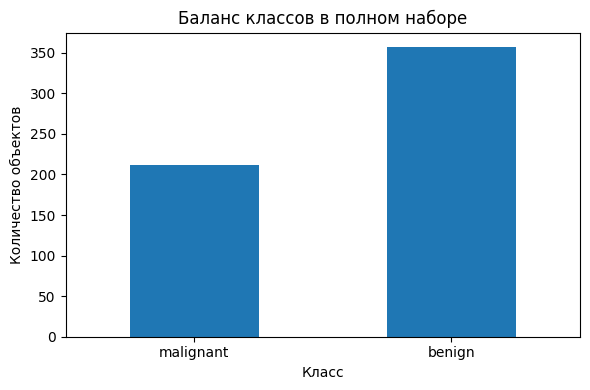

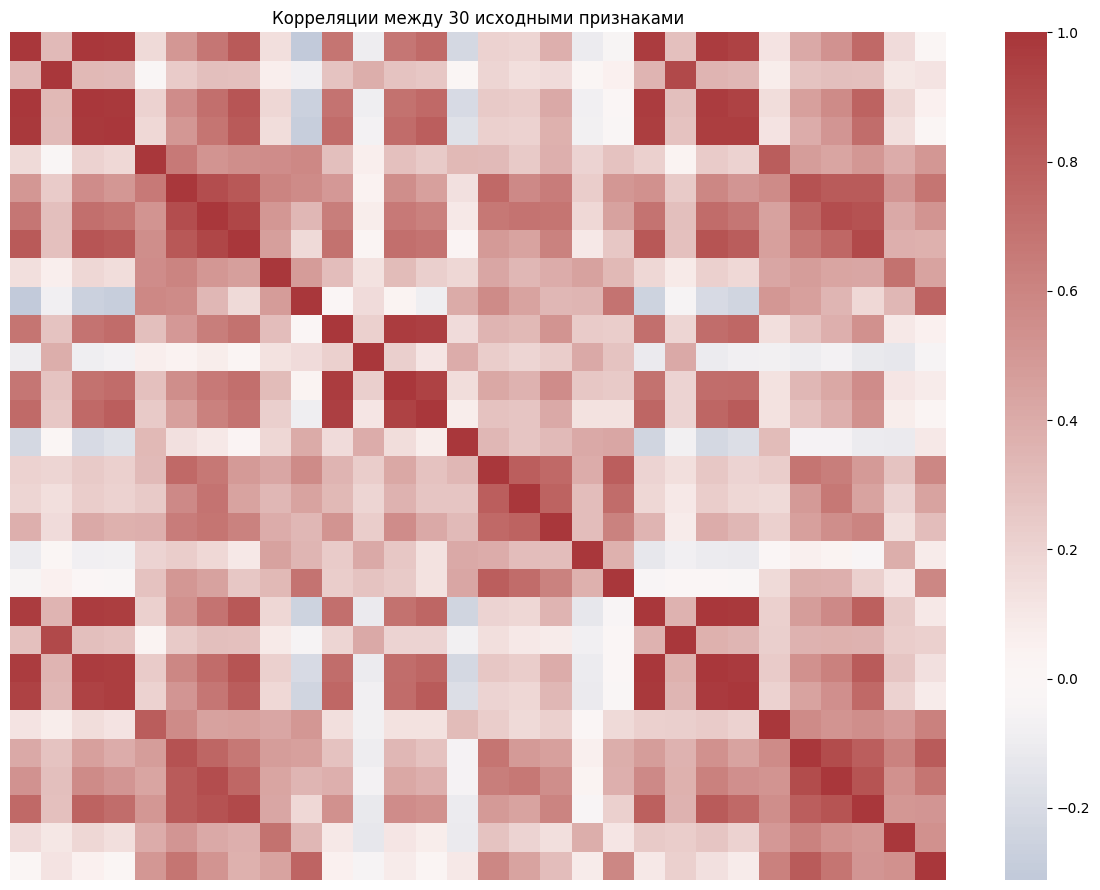

10 пар признаков с наибольшей абсолютной корреляцией:


,,abs_corr
mean radius,mean perimeter,0.998
worst radius,worst perimeter,0.994
mean radius,mean area,0.987
mean perimeter,mean area,0.987
worst radius,worst area,0.984
worst perimeter,worst area,0.978
radius error,perimeter error,0.973
mean perimeter,worst perimeter,0.970
mean radius,worst radius,0.970
mean perimeter,worst radius,0.969


,Пункт,Описание
0,Источник,Breast Cancer Wisconsin Diagnostic из sklearn....
1,Объём,"569 объектов, 30 вещественных признаков"
2,Целевая переменная,Бинарная: malignant (0) / benign (1)
3,Баланс классов,"malignant: 212, benign: 357"
4,Пропуски,0; в этой версии набора не обнаружены
5,Дубликаты,0 повторяющихся строк признаков
6,Тип признаков,Числовые измерения ядер клеток
7,Разделение,"75% train / 25% test, stratify=y, random_state=42"
8,Подбор,"StratifiedKFold: 5 folds, shuffle=True, random..."
9,Риски,Классы несбалансированы; признаки коррелируют;...


In [ ]:
# Базовый аудит: типы, пропуски, дубликаты, диапазоны и зависимости признаков.
print(f'Размер таблицы признаков: {X.shape[0]} объектов × {X.shape[1]} признаков')
print(f'Полностью одинаковых строк признаков: {X.duplicated().sum()}')
print(f'Пропусков во всех ячейках: {int(X.isna().sum().sum())}')

print('Типы данных:')
display(X.dtypes.value_counts().rename_axis('Тип').to_frame('Число признаков'))

print('Пропуски по столбцам (показаны только столбцы с пропусками):')
display(X.isna().sum().loc[lambda s: s > 0].to_frame('Пропусков'))

print('Описательная статистика признаков:')
stats = X.describe().T.rename(columns={'50%': 'median'})
display(stats[['mean', 'std', 'min', 'median', 'max']].round(3))

# Распределение классов: 0 = malignant, 1 = benign.
class_counts = y.map({0: 'malignant', 1: 'benign'}).value_counts().reindex(['malignant', 'benign'])
ax = class_counts.plot(kind='bar', figsize=(6, 4), rot=0)
ax.set_title('Баланс классов в полном наборе')
ax.set_xlabel('Класс')
ax.set_ylabel('Количество объектов')
plt.tight_layout()
plt.show()

# Корреляционная матрица нужна для обнаружения связанных характеристик.
plt.figure(figsize=(12, 9))
sns.heatmap(X.corr(), cmap='vlag', center=0, xticklabels=False, yticklabels=False)
plt.title('Корреляции между 30 исходными признаками')
plt.tight_layout()
plt.show()

corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = upper.stack().sort_values(ascending=False).head(10)
print('10 пар признаков с наибольшей абсолютной корреляцией:')
display(strong_pairs.rename('abs_corr').to_frame().round(3))

# Короткая data card на основе описания набора и проведённого аудита.
data_card = pd.DataFrame([
    ('Источник', 'Breast Cancer Wisconsin Diagnostic из sklearn.datasets'),
    ('Объём', f'{len(X)} объектов, {X.shape[1]} вещественных признаков'),
    ('Целевая переменная', 'Бинарная: malignant (0) / benign (1)'),
    ('Баланс классов', f'malignant: {(y == 0).sum()}, benign: {(y == 1).sum()}'),
    ('Пропуски', f'{int(X.isna().sum().sum())}; в этой версии набора не обнаружены'),
    ('Дубликаты', f'{int(X.duplicated().sum())} повторяющихся строк признаков'),
    ('Тип признаков', 'Числовые измерения ядер клеток'),
    ('Разделение', '75% train / 25% test, stratify=y, random_state=42'),
    ('Подбор', 'StratifiedKFold: 5 folds, shuffle=True, random_state=42'),
    ('Риски', 'Классы несбалансированы; признаки коррелируют; медицинское применение недопустимо без отдельной валидации')
], columns=['Пункт', 'Описание'])
display(data_card)

# Полные индексы train/test фиксируются в следующей ячейке после stratified split.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
train_indices = X_train.index.tolist()
test_indices = X_test.index.tolist()

print(f'Train: {X_train.shape}; test: {X_test.shape}')
print('Доли классов на train:')
display(y_train.map({0: 'malignant', 1: 'benign'}).value_counts(normalize=True).rename('Доля').to_frame().round(3))
print('Доли классов на test:')
display(y_test.map({0: 'malignant', 1: 'benign'}).value_counts(normalize=True).rename('Доля').to_frame().round(3))
print('Первые 12 индексов train:', train_indices[:12])
print('Первые 12 индексов test:', test_indices[:12])
print('Полные индексы остаются в переменных train_indices и test_indices.')

Train: (426, 30); test: (143, 30)
Доли классов на train:


,Доля
target,
benign,0.627
malignant,0.373


Доли классов на test:


,Доля
target,
benign,0.629
malignant,0.371


Первые 12 индексов train: [517, 287, 25, 253, 369, 489, 145, 0, 72, 192, 500, 39]
Первые 12 индексов test: [519, 408, 291, 518, 385, 535, 8, 127, 372, 398, 340, 431]
Полные индексы остаются в переменных train_indices и test_indices.


## 2. Baseline

In [ ]:
models = {
    'Dummy prior': DummyClassifier(strategy='prior'),
    'Logistic Regression': Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(max_iter=5000, class_weight='balanced', random_state=RANDOM_STATE))
    ])
}

baseline_rows = []
for model_name, estimator in models.items():
    result = cross_validate(
        estimator, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=-1
    )
    row = {'Модель': model_name}
    for metric_name in scoring:
        key = f'test_{metric_name}'
        row[f'{metric_name}, mean'] = result[key].mean()
        row[f'{metric_name}, std'] = result[key].std()
    row['fit_time, mean (s)'] = result['fit_time'].mean()
    baseline_rows.append(row)

baseline_summary = pd.DataFrame(baseline_rows).set_index('Модель')
display(baseline_summary.round(4))

print('Почему accuracy недостаточно: DummyClassifier может часто угадывать большинство (benign),')
print('но при этом иметь recall malignant около нуля. Поэтому дополнительно смотрим ROC-AUC,')
print('PR-AUC для malignant, recall и precision именно для злокачественного класса.')

,"roc_auc, mean","roc_auc, std","ap_malignant, mean","ap_malignant, std","recall_malignant, mean","recall_malignant, std","precision_malignant, mean","precision_malignant, std","accuracy, mean","accuracy, std","fit_time, mean (s)"
Модель,,,,,,,,,,,
Dummy prior,0.5000,0.0000,0.3732,0.0046,0.0000,0.0000,0.0000,0.0000,0.6268,0.0046,0.0011
Logistic Regression,0.9959,0.0039,0.9949,0.0037,0.9623,0.0124,0.9752,0.0228,0.9765,0.0074,0.0053


Почему accuracy недостаточно: DummyClassifier может часто угадывать большинство (benign),
но при этом иметь recall malignant около нуля. Поэтому дополнительно смотрим ROC-AUC,
PR-AUC для malignant, recall и precision именно для злокачественного класса.


## 3. Масштабирование

In [ ]:
scalers = {
    'none': 'passthrough',
    'standard': StandardScaler(),
    'robust': RobustScaler(),
    'minmax': MinMaxScaler()
}

scaler_rows = []
for scaler_name, scaler in scalers.items():
    estimator = Pipeline([
        ('scale', scaler),
        ('model', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced'))
    ])
    result = cross_validate(
        estimator, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=-1
    )
    scaler_rows.append({
        'Scaler': scaler_name,
        'ROC-AUC mean': result['test_roc_auc'].mean(),
        'ROC-AUC std': result['test_roc_auc'].std(),
        'Recall malignant': result['test_recall_malignant'].mean(),
        'Precision malignant': result['test_precision_malignant'].mean(),
        'PR-AUC malignant': result['test_ap_malignant'].mean(),
        'Fit time mean (s)': result['fit_time'].mean()
    })

scaler_summary = pd.DataFrame(scaler_rows).sort_values('ROC-AUC mean', ascending=False).set_index('Scaler')
display(scaler_summary.round(4))

print('У SVM с RBF-ядром масштаб особенно важен: расстояния между объектами влияют на ядро.')
print('Если признаки измеряются в разных единицах, крупномасштабные признаки могут доминировать.')

,ROC-AUC mean,ROC-AUC std,Recall malignant,Precision malignant,PR-AUC malignant,Fit time mean (s)
Scaler,,,,,,
minmax,0.9958,0.0037,0.9562,0.9752,0.9945,0.0036
robust,0.9952,0.0034,0.9562,0.9687,0.9937,0.0064
standard,0.9948,0.0035,0.9562,0.9687,0.9934,0.0039
none,0.9689,0.0089,0.8802,0.8934,0.9571,0.0045


У SVM с RBF-ядром масштаб особенно важен: расстояния между объектами влияют на ядро.
Если признаки измеряются в разных единицах, крупномасштабные признаки могут доминировать.


## 4. LinearSVC и C

,penalty,C,mean_train_roc_auc,mean_cv_roc_auc,std_cv_roc_auc,mean_nonzero_coef_L1,mean_coef_norm_L2,fit_time_mean
0,l1,0.0001,0.5000,0.5000,0.0000,0.0,NaN,0.0042
1,l1,0.0010,0.5000,0.5000,0.0000,0.0,NaN,0.0037
2,l1,0.0100,0.9896,0.9877,0.0120,4.2,NaN,0.0042
3,l1,0.1000,0.9969,0.9951,0.0037,10.4,NaN,0.0042
4,l1,1.0000,0.9994,0.9927,0.0057,18.4,NaN,0.0119
5,l1,10.0000,1.0000,0.9868,0.0103,22.8,NaN,0.0844
6,l1,100.0000,1.0000,0.9856,0.0097,25.2,NaN,0.1293
7,l1,1000.0000,1.0000,0.9847,0.0103,30.0,NaN,0.0418
8,l2,0.0001,0.9869,0.9858,0.0109,NaN,0.1057,0.0030
9,l2,0.0010,0.9936,0.9933,0.0042,NaN,0.2798,0.0031


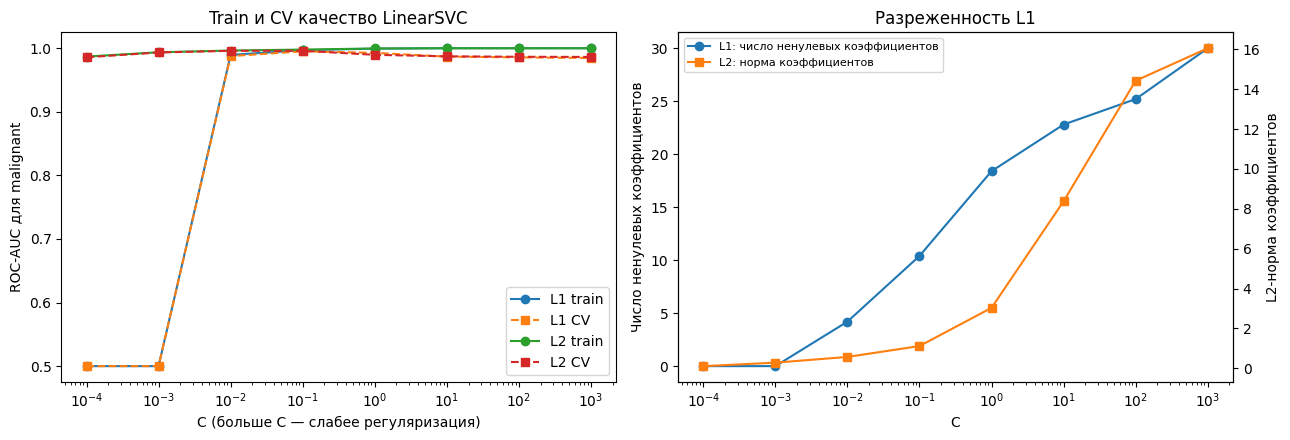

Лучший LinearSVC по среднему CV ROC-AUC: penalty=l2, C=0.1.


In [ ]:
# Проверяем L1 и L2-регуляризацию при одном и том же наборе C.
c_grid = np.logspace(-4, 3, 8)
linear_rows = []
linear_cv_estimators = {}

for penalty in ['l1', 'l2']:
    for C_value in c_grid:
        estimator = Pipeline([
            ('scale', StandardScaler()),
            ('model', LinearSVC(
                penalty=penalty, dual=False, C=C_value,
                class_weight='balanced', max_iter=20000,
                random_state=RANDOM_STATE
            ))
        ])
        result = cross_validate(
            estimator, X_train, y_train, cv=cv,
            scoring={'roc_auc': malignant_roc_auc},
            return_train_score=True, return_estimator=True, n_jobs=-1
        )
        linear_cv_estimators[(penalty, C_value)] = result['estimator']
        coefficient_stats = []
        for fitted_pipeline in result['estimator']:
            coef = fitted_pipeline.named_steps['model'].coef_.ravel()
            if penalty == 'l1':
                coefficient_stats.append(int(np.sum(np.abs(coef) > 1e-8)))
            else:
                coefficient_stats.append(float(np.linalg.norm(coef, ord=2)))
        linear_rows.append({
            'penalty': penalty,
            'C': C_value,
            'mean_train_roc_auc': result['train_roc_auc'].mean(),
            'mean_cv_roc_auc': result['test_roc_auc'].mean(),
            'std_cv_roc_auc': result['test_roc_auc'].std(),
            'mean_nonzero_coef_L1': np.mean(coefficient_stats) if penalty == 'l1' else np.nan,
            'mean_coef_norm_L2': np.mean(coefficient_stats) if penalty == 'l2' else np.nan,
            'fit_time_mean': result['fit_time'].mean()
        })

linear_curve = pd.DataFrame(linear_rows)
display(linear_curve.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for penalty in ['l1', 'l2']:
    subset = linear_curve[linear_curve['penalty'] == penalty].sort_values('C')
    axes[0].plot(subset['C'], subset['mean_train_roc_auc'], marker='o', label=f'{penalty.upper()} train')
    axes[0].plot(subset['C'], subset['mean_cv_roc_auc'], marker='s', linestyle='--', label=f'{penalty.upper()} CV')
axes[0].set_xscale('log')
axes[0].set_xlabel('C (больше C — слабее регуляризация)')
axes[0].set_ylabel('ROC-AUC для malignant')
axes[0].set_title('Train и CV качество LinearSVC')
axes[0].legend()

l1_curve = linear_curve[linear_curve['penalty'] == 'l1'].sort_values('C')
l2_curve = linear_curve[linear_curve['penalty'] == 'l2'].sort_values('C')
axes[1].plot(l1_curve['C'], l1_curve['mean_nonzero_coef_L1'], marker='o', label='L1: число ненулевых коэффициентов')
axes[1].set_xscale('log')
axes[1].set_xlabel('C')
axes[1].set_ylabel('Число ненулевых коэффициентов')
axes[1].set_title('Разреженность L1')
ax2 = axes[1].twinx()
ax2.plot(l2_curve['C'], l2_curve['mean_coef_norm_L2'], marker='s', color='tab:orange', label='L2: норма коэффициентов')
ax2.set_ylabel('L2-норма коэффициентов')
lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc='best', fontsize=8)
plt.tight_layout()
plt.show()

best_linear_row = linear_curve.loc[linear_curve['mean_cv_roc_auc'].idxmax()]
best_linear_penalty = best_linear_row['penalty']
best_linear_C = float(best_linear_row['C'])
print(f'Лучший LinearSVC по среднему CV ROC-AUC: penalty={best_linear_penalty}, C={best_linear_C:g}.')

,coef,abs(coef)
worst texture,-0.4035,0.4035
radius error,-0.3788,0.3788
area error,-0.3463,0.3463
mean compactness,0.3347,0.3347
worst symmetry,-0.3182,0.3182
worst concave points,-0.3154,0.3154
worst area,-0.3034,0.3034
worst radius,-0.2852,0.2852
worst concavity,-0.2583,0.2583
mean concave points,-0.2353,0.2353


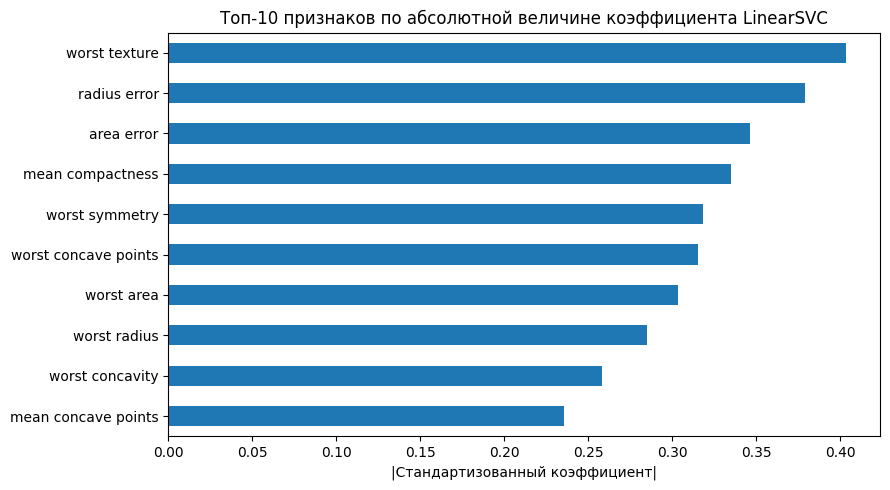

Сильно коррелированные пары среди top-10 (если есть):


abs_corr
worst area           worst radius            0.986
radius error         area error              0.954
worst concave points mean concave points     0.913
                     worst concavity         0.863

Коэффициенты показывают вклад признака в линейную границу при прочих равных,
но коррелированные признаки могут делить между собой вес. Это не причинная интерпретация.


In [ ]:
# Обучаем лучший вариант LinearSVC только на train и смотрим стандартизованные коэффициенты.
best_linear_model = Pipeline([
    ('scale', StandardScaler()),
    ('model', LinearSVC(
        penalty=best_linear_penalty, dual=False, C=best_linear_C,
        class_weight='balanced', max_iter=20000,
        random_state=RANDOM_STATE
    ))
])
best_linear_model.fit(X_train, y_train)
linear_coef = pd.Series(
    best_linear_model.named_steps['model'].coef_.ravel(),
    index=X_train.columns,
    name='coef'
)
top_linear_features = linear_coef.abs().sort_values(ascending=False).head(10)
display(pd.DataFrame({
    'coef': linear_coef.loc[top_linear_features.index],
    'abs(coef)': top_linear_features
}).sort_values('abs(coef)', ascending=False).round(4))

plt.figure(figsize=(9, 5))
top_linear_features.sort_values().plot(kind='barh')
plt.title('Топ-10 признаков по абсолютной величине коэффициента LinearSVC')
plt.xlabel('|Стандартизованный коэффициент|')
plt.tight_layout()
plt.show()

# Проверяем, есть ли сильные взаимные корреляции среди выбранных признаков.
top_corr = X_train[top_linear_features.index].corr().abs()
pairs = top_corr.where(np.triu(np.ones(top_corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print('Сильно коррелированные пары среди top-10 (если есть):')
display(pairs[pairs >= 0.85].rename('abs_corr').to_frame().round(3))
print('Коэффициенты показывают вклад признака в линейную границу при прочих равных,')
print('но коррелированные признаки могут делить между собой вес. Это не причинная интерпретация.')

## 5. RBF SVM: совместный поиск C и gamma

In [ ]:
rbf_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', SVC(kernel='rbf', class_weight='balanced'))
])
param_grid = {
    'model__C': np.logspace(-3, 3, 7),
    'model__gamma': np.logspace(-4, 1, 6)
}
search = GridSearchCV(
    rbf_pipe, param_grid, scoring=malignant_roc_auc, cv=cv,
    n_jobs=-1, return_train_score=True, refit=True
)
search.fit(X_train, y_train)
print('GridSearchCV завершён. Test здесь не использовался.')
print(f'Лучший средний CV ROC-AUC: {search.best_score_:.4f}')

GridSearchCV завершён. Test здесь не использовался.
Лучший средний CV ROC-AUC: 0.9971


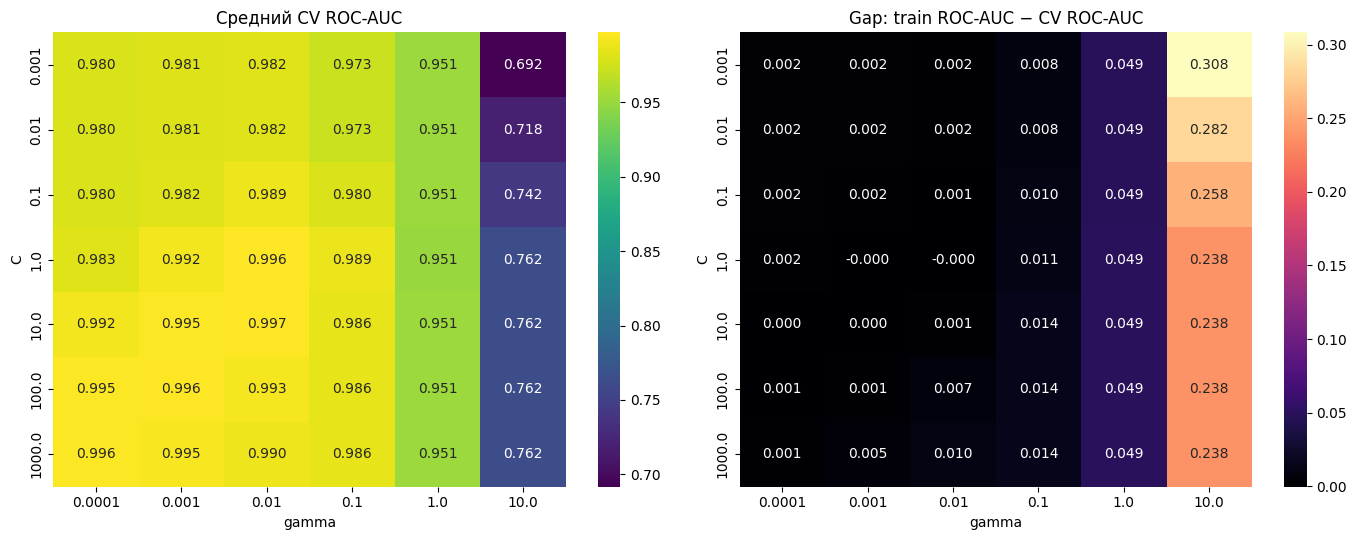

Плато — соседняя область параметров с близким CV score; оно обычно надёжнее одиночного резкого пика.


In [ ]:
# Тепловая карта среднего validation ROC-AUC.
rbf_results = pd.DataFrame(search.cv_results_)
score_heatmap = rbf_results.pivot(index='param_model__C', columns='param_model__gamma', values='mean_test_score')
gap_heatmap = rbf_results.assign(gap=rbf_results['mean_train_score'] - rbf_results['mean_test_score']).pivot(
    index='param_model__C', columns='param_model__gamma', values='gap'
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(score_heatmap, annot=True, fmt='.3f', cmap='viridis', ax=axes[0])
axes[0].set_title('Средний CV ROC-AUC')
axes[0].set_xlabel('gamma')
axes[0].set_ylabel('C')
sns.heatmap(gap_heatmap, annot=True, fmt='.3f', cmap='magma', ax=axes[1])
axes[1].set_title('Gap: train ROC-AUC − CV ROC-AUC')
axes[1].set_xlabel('gamma')
axes[1].set_ylabel('C')
plt.tight_layout()
plt.show()

print('Плато — соседняя область параметров с близким CV score; оно обычно надёжнее одиночного резкого пика.')

In [ ]:
print('Лучшие параметры:', search.best_params_)
print(f'Лучший CV ROC-AUC: {search.best_score_:.4f}')
rbf_best_svc = search.best_estimator_.named_steps['model']
print('Число support vectors по классам [malignant, benign] в refit-модели:', rbf_best_svc.n_support_)
print('Всего support vectors:', int(rbf_best_svc.n_support_.sum()))

best_rbf_result = rbf_results.loc[search.best_index_]
print(f"Средний train ROC-AUC в лучшей точке: {best_rbf_result['mean_train_score']:.4f}")
print(f"Средний CV ROC-AUC в лучшей точке: {best_rbf_result['mean_test_score']:.4f}")

Лучшие параметры: {'model__C': np.float64(10.0), 'model__gamma': np.float64(0.01)}
Лучший CV ROC-AUC: 0.9971
Число support vectors по классам [malignant, benign] в refit-модели: [21 32]
Всего support vectors: 53
Средний train ROC-AUC в лучшей точке: 0.9983
Средний CV ROC-AUC в лучшей точке: 0.9971


## 6. Сравнение ядер

In [ ]:
# Отдельные сетки для каждого ядра; CV и целевая метрика во всех случаях одинаковы.
kernel_grids = {
    'linear': {'model__C': np.logspace(-3, 3, 7)},
    'poly': {
        'model__C': [0.1, 1, 10],
        'model__degree': [2, 3, 4],
        'model__gamma': ['scale', 0.01],
        'model__coef0': [0, 1]
    },
    'rbf': {
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 0.001, 0.01, 0.1]
    }
}

kernel_searches = {}
kernel_rows = []
for kernel_name, grid in kernel_grids.items():
    pipeline = Pipeline([
        ('scale', StandardScaler()),
        ('model', SVC(kernel=kernel_name, class_weight='balanced'))
    ])
    kernel_search = GridSearchCV(
        pipeline, grid, scoring={
            'roc_auc': malignant_roc_auc,
            'recall_malignant': malignant_recall,
            'precision_malignant': malignant_precision,
            'ap_malignant': malignant_average_precision
        },
        refit='roc_auc', cv=cv, n_jobs=-1, return_train_score=False
    )
    kernel_search.fit(X_train, y_train)
    kernel_searches[kernel_name] = kernel_search
    best_idx = kernel_search.best_index_
    best_svc = kernel_search.best_estimator_.named_steps['model']
    kernel_rows.append({
        'Ядро': kernel_name,
        'CV ROC-AUC': kernel_search.cv_results_['mean_test_roc_auc'][best_idx],
        'CV recall malignant': kernel_search.cv_results_['mean_test_recall_malignant'][best_idx],
        'CV precision malignant': kernel_search.cv_results_['mean_test_precision_malignant'][best_idx],
        'CV PR-AUC malignant': kernel_search.cv_results_['mean_test_ap_malignant'][best_idx],
        'Fit time mean (s)': kernel_search.cv_results_['mean_fit_time'][best_idx],
        'Support vectors (train refit)': int(best_svc.n_support_.sum()),
        'Лучшие параметры': str(kernel_search.best_params_)
    })

kernel_summary = pd.DataFrame(kernel_rows).set_index('Ядро').sort_values('CV ROC-AUC', ascending=False)
display(kernel_summary.round(4))

print('RBF гибкое и часто подходит для нелинейных границ. Poly может быть полезно,')
print('если полиномиальные взаимодействия оправданы, но более сложное ядро не гарантирует лучшего обобщения.')

,CV ROC-AUC,CV recall malignant,CV precision malignant,CV PR-AUC malignant,Fit time mean (s),Support vectors (train refit),Лучшие параметры
Ядро,,,,,,,
poly,0.9972,0.9625,0.9754,0.9966,0.0041,48,"{'model__C': 10, 'model__coef0': 1, 'model__de..."
rbf,0.9971,0.9500,0.9752,0.9965,0.0030,53,"{'model__C': 10, 'model__gamma': 0.01}"
linear,0.9960,0.9562,0.9752,0.9949,0.0037,51,{'model__C': np.float64(0.1)}


RBF гибкое и часто подходит для нелинейных границ. Poly может быть полезно,
если полиномиальные взаимодействия оправданы, но более сложное ядро не гарантирует лучшего обобщения.


## 7. Filter selection внутри Pipeline

Лучший результат Filter selection:
Параметры: {'model__C': 10, 'model__gamma': 0.01, 'select__k': 'all', 'select__score_func': <function f_classif at 0x7f91b47ed440>}
CV ROC-AUC: 0.9971


,selection_method,k,best_cv_roc_auc
0,f_classif,5,0.9873
1,f_classif,10,0.9858
2,f_classif,15,0.9916
3,f_classif,20,0.9966
4,f_classif,25,0.9970
5,f_classif,all,0.9971
6,mutual_info,5,0.9876
7,mutual_info,10,0.9865
8,mutual_info,15,0.9916
9,mutual_info,20,0.9960


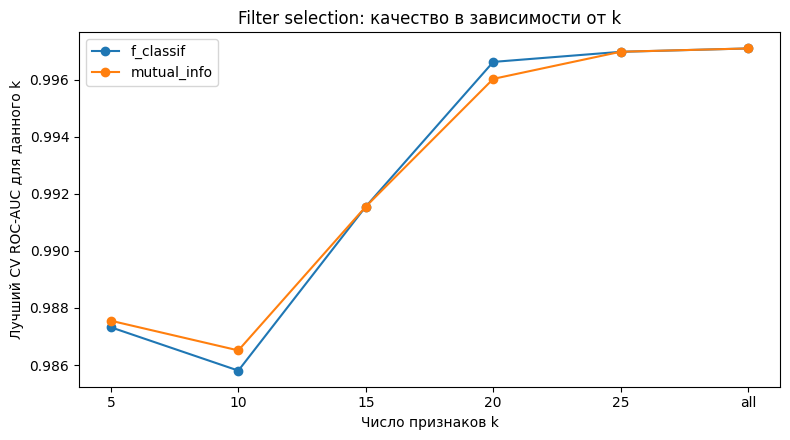

Выбрано признаков: 30
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
f_classif оценивает линейную связь признака с классом; mutual information может учитывать нелинейную связь.


In [ ]:
filter_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectKBest()),
    ('model', SVC(kernel='rbf', class_weight='balanced'))
])
filter_grid = [
    {'select__score_func': [f_classif], 'select__k': [5, 10, 15, 20, 25, 'all'],
     'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01, 0.1]},
    {'select__score_func': [mutual_info_fixed], 'select__k': [5, 10, 15, 20, 25, 'all'],
     'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01, 0.1]}
]
filter_search = GridSearchCV(
    filter_pipe, filter_grid, scoring=malignant_roc_auc, cv=cv,
    n_jobs=-1, return_train_score=True, refit=True
)
filter_search.fit(X_train, y_train)
print('Лучший результат Filter selection:')
print('Параметры:', filter_search.best_params_)
print(f'CV ROC-AUC: {filter_search.best_score_:.4f}')

filter_results = pd.DataFrame(filter_search.cv_results_)
filter_results['selection_method'] = filter_results['param_select__score_func'].map(
    lambda func: 'f_classif' if func is f_classif else 'mutual_info'
)
# Для каждого k берём лучший CV score среди C и gamma.
filter_curve = (filter_results.groupby(['selection_method', 'param_select__k'], dropna=False)['mean_test_score']
                .max().reset_index().rename(columns={'param_select__k': 'k', 'mean_test_score': 'best_cv_roc_auc'}))
filter_curve['k_label'] = filter_curve['k'].astype(str)
filter_curve['k_label'] = pd.Categorical(filter_curve['k_label'], categories=['5', '10', '15', '20', '25', 'all'], ordered=True)
filter_curve = filter_curve.sort_values(['selection_method', 'k_label'])
display(filter_curve[['selection_method', 'k', 'best_cv_roc_auc']].round(4))

plt.figure(figsize=(8, 4.5))
for method in ['f_classif', 'mutual_info']:
    subset = filter_curve[filter_curve['selection_method'] == method]
    plt.plot(subset['k_label'].astype(str), subset['best_cv_roc_auc'], marker='o', label=method)
plt.xlabel('Число признаков k')
plt.ylabel('Лучший CV ROC-AUC для данного k')
plt.title('Filter selection: качество в зависимости от k')
plt.legend()
plt.tight_layout()
plt.show()

filter_selector = filter_search.best_estimator_.named_steps['select']
selected_filter_features = X_train.columns[filter_selector.get_support()].tolist()
print(f'Выбрано признаков: {len(selected_filter_features)}')
print(selected_filter_features)
print('f_classif оценивает линейную связь признака с классом; mutual information может учитывать нелинейную связь.')

## 8. Embedded selection и RFECV

In [ ]:
# Embedded selection: отбор происходит внутри каждого обучающего fold.
embedded = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectFromModel(LinearSVC(
        penalty='l1', dual=False, C=0.05, max_iter=20000,
        class_weight='balanced', random_state=RANDOM_STATE
    ))),
    ('model', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced'))
])
embedded_cv = cross_validate(
    embedded, X_train, y_train, cv=cv, scoring=scoring,
    return_estimator=True, return_train_score=False, n_jobs=-1
)
embedded_summary = pd.DataFrame({
    'Метрика': list(scoring.keys()),
    'CV mean': [embedded_cv[f'test_{metric}'].mean() for metric in scoring],
    'CV std': [embedded_cv[f'test_{metric}'].std() for metric in scoring]
})
display(embedded_summary.round(4))
print(f"Среднее время fit для embedded-пайплайна на fold: {embedded_cv['fit_time'].mean():.4f} с")

embedded_masks = np.vstack([
    fitted.named_steps['select'].get_support() for fitted in embedded_cv['estimator']
])
embedded_frequency = pd.Series(embedded_masks.mean(axis=0), index=X_train.columns).sort_values(ascending=False)
print('Число выбранных признаков по внешним folds:', embedded_masks.sum(axis=1).tolist())
print('Признаки, выбранные минимум в 4 из 5 folds:')
display(embedded_frequency[embedded_frequency >= 0.8].rename('Частота выбора').to_frame())

embedded.fit(X_train, y_train)
embedded_selected_features = X_train.columns[embedded.named_steps['select'].get_support()].tolist()
print(f'После fit на всём train выбрано {len(embedded_selected_features)} признаков:')
print(embedded_selected_features)

,Метрика,CV mean,CV std
0,roc_auc,0.9965,0.0038
1,ap_malignant,0.9953,0.0045
2,recall_malignant,0.9625,0.0234
3,precision_malignant,0.9631,0.0225
4,accuracy,0.9718,0.0057


Среднее время fit для embedded-пайплайна на fold: 0.0060 с
Число выбранных признаков по внешним folds: [9, 7, 10, 8, 10]
Признаки, выбранные минимум в 4 из 5 folds:


,Частота выбора
mean concave points,1.0
worst symmetry,1.0
worst smoothness,1.0
worst concave points,1.0
worst texture,1.0
worst radius,1.0
radius error,0.8


После fit на всём train выбрано 10 признаков:
['mean texture', 'mean concave points', 'radius error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']


In [ ]:
# RFECV — wrapper-метод. StandardScaler размещён внутри LinearSVC estimator,
# поэтому он заново обучается на каждом внутреннем fold и не подглядывает в validation.
rfecv_selector = RFECV(
    estimator=Pipeline([
        ('scale', StandardScaler()),
        ('linear', LinearSVC(
            penalty='l2', dual=False, C=1,
            class_weight='balanced', max_iter=20000,
            random_state=RANDOM_STATE
        ))
    ]),
    importance_getter='named_steps.linear.coef_',
    step=2, min_features_to_select=5, cv=cv,
    scoring=malignant_roc_auc, n_jobs=1
)
rfecv_pipe = Pipeline([
    ('select', rfecv_selector),
    ('scale', StandardScaler()),
    ('model', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced'))
])
rfecv_cv = cross_validate(
    rfecv_pipe, X_train, y_train, cv=cv, scoring=scoring,
    return_estimator=True, return_train_score=False, n_jobs=1
)
rfecv_summary = pd.DataFrame({
    'Метрика': list(scoring.keys()),
    'CV mean': [rfecv_cv[f'test_{metric}'].mean() for metric in scoring],
    'CV std': [rfecv_cv[f'test_{metric}'].std() for metric in scoring]
})
display(rfecv_summary.round(4))
print(f"Среднее время fit для RFECV-пайплайна на fold (включая внутренний CV): {rfecv_cv['fit_time'].mean():.4f} с")

rfecv_masks = np.vstack([
    fitted.named_steps['select'].get_support() for fitted in rfecv_cv['estimator']
])
rfecv_frequency = pd.Series(rfecv_masks.mean(axis=0), index=X_train.columns).sort_values(ascending=False)
print('Число выбранных признаков по внешним folds:', rfecv_masks.sum(axis=1).tolist())
print('Признаки, выбранные минимум в 4 из 5 folds:')
display(rfecv_frequency[rfecv_frequency >= 0.8].rename('Частота выбора').to_frame())

rfecv_pipe.fit(X_train, y_train)
rfecv_selected_features = X_train.columns[rfecv_pipe.named_steps['select'].get_support()].tolist()
print(f'RFECV выбрал {len(rfecv_selected_features)} признаков после fit на всём train:')
print(rfecv_selected_features)
print('RFECV ищет набор признаков совместно с линейным estimator и поэтому вычислительно дороже filter-методов.')

,Метрика,CV mean,CV std
0,roc_auc,0.9939,0.0031
1,ap_malignant,0.9917,0.0041
2,recall_malignant,0.9500,0.0250
3,precision_malignant,0.9568,0.0306
4,accuracy,0.9648,0.0129


Среднее время fit для RFECV-пайплайна на fold (включая внутренний CV): 0.2046 с
Число выбранных признаков по внешним folds: [22, 8, 20, 8, 22]
Признаки, выбранные минимум в 4 из 5 folds:


,Частота выбора
mean compactness,1.0
area error,1.0
radius error,1.0
worst texture,1.0
worst area,1.0
mean concavity,0.8
worst radius,0.8
worst concavity,0.8
perimeter error,0.8
worst concave points,0.8


RFECV выбрал 14 признаков после fit на всём train:
['mean compactness', 'mean concavity', 'mean concave points', 'mean fractal dimension', 'radius error', 'perimeter error', 'area error', 'concavity error', 'concave points error', 'worst radius', 'worst texture', 'worst area', 'worst concavity', 'worst symmetry']
RFECV ищет набор признаков совместно с линейным estimator и поэтому вычислительно дороже filter-методов.


## 9. PCA: extraction, а не selection

In [ ]:
# PCA извлекает новые компоненты; это не отбор исходных признаков.
pca_rows = []
pca_models = {}
for variance in [None, 0.90, 0.95, 0.99]:
    steps = [('scale', StandardScaler())]
    if variance is not None:
        steps.append(('pca', PCA(n_components=variance, random_state=RANDOM_STATE)))
    steps.append(('model', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced')))
    estimator = Pipeline(steps)
    result = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    estimator.fit(X_train, y_train)
    component_count = X_train.shape[1] if variance is None else estimator.named_steps['pca'].n_components_
    name = 'Исходные признаки' if variance is None else f'PCA {variance:.0%}'
    pca_models[name] = estimator
    pca_rows.append({
        'Вариант': name,
        'Число компонент/признаков': component_count,
        'CV ROC-AUC': result['test_roc_auc'].mean(),
        'ROC-AUC std': result['test_roc_auc'].std(),
        'Recall malignant': result['test_recall_malignant'].mean(),
        'PR-AUC malignant': result['test_ap_malignant'].mean(),
        'Fit time mean (s)': result['fit_time'].mean()
    })
pca_summary = pd.DataFrame(pca_rows).set_index('Вариант')
display(pca_summary.round(4))

# Две осмысленные инженерные характеристики добавляются внутри Pipeline.
def engineer_features(frame):
    frame = frame.copy()
    # Отношение площади к квадрату периметра — простая безразмерная характеристика формы.
    frame['mean_area_perimeter2_ratio'] = frame['mean area'] / (frame['mean perimeter'] ** 2 + 1e-12)
    # Логарифм площади сглаживает правый хвост распределения положительного признака.
    frame['log_worst_area'] = np.log1p(frame['worst area'])
    return frame

engineered_pipe = Pipeline([
    ('features', FunctionTransformer(engineer_features, validate=False)),
    ('scale', StandardScaler()),
    ('model', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced'))
])
engineered_result = cross_validate(engineered_pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
engineered_pipe.fit(X_train, y_train)
engineered_summary = pd.DataFrame([{
    'Вариант': 'Исходные + 2 engineered',
    'CV ROC-AUC': engineered_result['test_roc_auc'].mean(),
    'ROC-AUC std': engineered_result['test_roc_auc'].std(),
    'Recall malignant': engineered_result['test_recall_malignant'].mean(),
    'PR-AUC malignant': engineered_result['test_ap_malignant'].mean(),
    'Fit time mean (s)': engineered_result['fit_time'].mean()
}]).set_index('Вариант')
display(engineered_summary.round(4))
print('PCA уменьшает размерность ценой потери прямой интерпретируемости компонент;')
print('добавленные признаки сохраняют понятный смысл, но их польза определяется только CV.')

,Число компонент/признаков,CV ROC-AUC,ROC-AUC std,Recall malignant,PR-AUC malignant,Fit time mean (s)
Вариант,,,,,,
Исходные признаки,30,0.9948,0.0035,0.9562,0.9934,0.0046
PCA 90%,7,0.9946,0.0030,0.9562,0.9931,0.0040
PCA 95%,10,0.9952,0.0035,0.9688,0.9941,0.0038
PCA 99%,17,0.9950,0.0036,0.9562,0.9936,0.0038


,CV ROC-AUC,ROC-AUC std,Recall malignant,PR-AUC malignant,Fit time mean (s)
Вариант,,,,,
Исходные + 2 engineered,0.9958,0.0031,0.9562,0.9944,0.0042


PCA уменьшает размерность ценой потери прямой интерпретируемости компонент;
добавленные признаки сохраняют понятный смысл, но их польза определяется только CV.


## 10. Out-of-fold порог

Зафиксированный порог для malignant: -0.186387
OOF recall malignant: 0.9748
OOF precision malignant: 0.9748


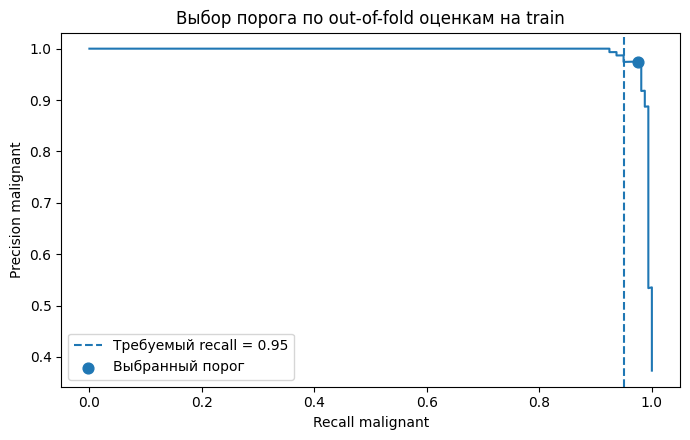

In [ ]:
# Фиксируем итоговую модель до обращения к test.
# В качестве итоговой берём RBF-SVM с параметрами, подобранными GridSearchCV только на train.
best_model = clone(search.best_estimator_)

# Out-of-fold decision scores для train. Порог не подбирается по test.
oof_score_benign = cross_val_predict(
    best_model, X_train, y_train, cv=cv,
    method='decision_function', n_jobs=-1
)
score_malignant_oof = -np.asarray(oof_score_benign)
y_malignant_train = (np.asarray(y_train) == 0).astype(int)

precision_values, recall_values, thresholds = precision_recall_curve(
    y_malignant_train, score_malignant_oof
)
# У precision/recall на одну точку больше, чем у массива thresholds.
valid_positions = np.flatnonzero(recall_values[:-1] >= 0.95)
if len(valid_positions) == 0:
    # Обычно такой случай не возникает; это безопасный резервный вариант.
    selected_position = int(np.argmax(recall_values[:-1]))
else:
    # Среди порогов, дающих recall >= 0.95, выбираем максимальную precision.
    selected_position = int(valid_positions[np.argmax(precision_values[valid_positions])])
threshold_malignant = float(thresholds[selected_position])
threshold_oof_recall = float(recall_values[selected_position])
threshold_oof_precision = float(precision_values[selected_position])

print(f'Зафиксированный порог для malignant: {threshold_malignant:.6f}')
print(f'OOF recall malignant: {threshold_oof_recall:.4f}')
print(f'OOF precision malignant: {threshold_oof_precision:.4f}')
if threshold_oof_recall < 0.95:
    print('Внимание: на доступных OOF оценках не удалось обеспечить recall >= 0.95; показан ближайший достижимый вариант.')

plt.figure(figsize=(7, 4.5))
plt.plot(recall_values, precision_values)
plt.axvline(0.95, linestyle='--', label='Требуемый recall = 0.95')
plt.scatter([threshold_oof_recall], [threshold_oof_precision], s=60, label='Выбранный порог')
plt.xlabel('Recall malignant')
plt.ylabel('Precision malignant')
plt.title('Выбор порога по out-of-fold оценкам на train')
plt.legend()
plt.tight_layout()
plt.show()

## 11. Финальная оценка на test — открыть только сейчас

,Test value
ROC-AUC malignant,0.9981
PR-AUC malignant,0.9972
Recall malignant,0.9811
Precision malignant,0.9123
Accuracy,0.9580


Classification report при выбранном пороге (сначала malignant, затем benign):
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.95        53
      benign       0.99      0.94      0.97        90

    accuracy                           0.96       143
   macro avg       0.95      0.96      0.96       143
weighted avg       0.96      0.96      0.96       143



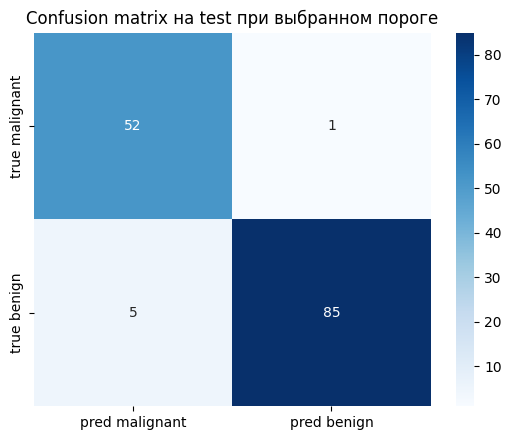

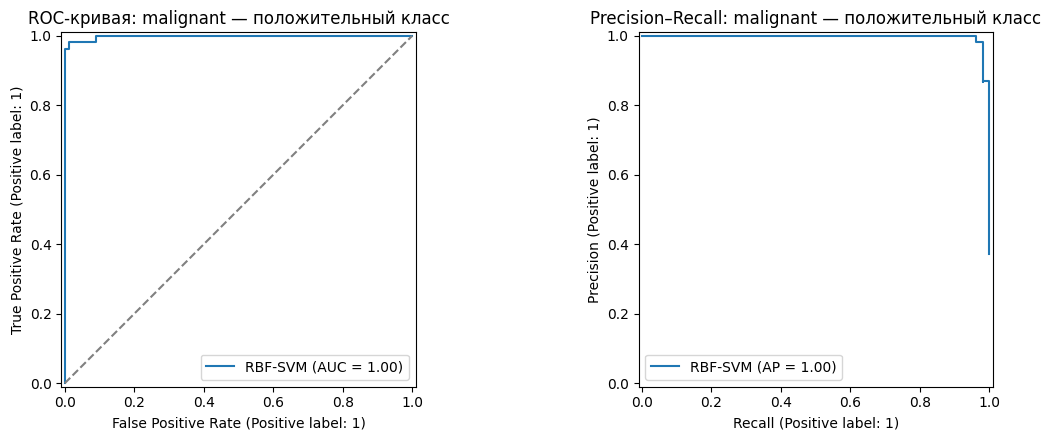

Сравнение: порог 0 — стандартное решение SVC; выбранный порог настроен на train OOF.
Порог 0: recall malignant = 0.9811, precision malignant = 0.9630
Выбранный порог: recall malignant = 0.9811, precision malignant = 0.9123
Изменение порога обычно повышает recall ценой большего количества ложноположительных ошибок.


In [ ]:
# Это единственная ячейка, в которой используем X_test и y_test для итоговой оценки.
final_model = clone(best_model)
final_model.fit(X_train, y_train)
score_malignant_test = -np.asarray(final_model.decision_function(X_test))
y_malignant_test = (np.asarray(y_test) == 0).astype(int)

# Правило применения зафиксированного порога: предсказать malignant при score >= threshold.
y_pred_malignant_test = (score_malignant_test >= threshold_malignant).astype(int)
y_pred_test = np.where(y_pred_malignant_test == 1, 0, 1)

final_test_metrics = {
    'ROC-AUC malignant': roc_auc_score(y_malignant_test, score_malignant_test),
    'PR-AUC malignant': average_precision_score(y_malignant_test, score_malignant_test),
    'Recall malignant': recall_score(y_malignant_test, y_pred_malignant_test, zero_division=0),
    'Precision malignant': precision_score(y_malignant_test, y_pred_malignant_test, zero_division=0),
    'Accuracy': np.mean(np.asarray(y_test) == y_pred_test)
}
display(pd.Series(final_test_metrics, name='Test value').to_frame().round(4))

print('Classification report при выбранном пороге (сначала malignant, затем benign):')
print(classification_report(
    y_test, y_pred_test, labels=[0, 1],
    target_names=['malignant', 'benign'], zero_division=0
))
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['pred malignant', 'pred benign'],
            yticklabels=['true malignant', 'true benign'])
plt.title('Confusion matrix на test при выбранном пороге')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_malignant_test, score_malignant_test, ax=axes[0], name='RBF-SVM')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[0].set_title('ROC-кривая: malignant — положительный класс')
PrecisionRecallDisplay.from_predictions(y_malignant_test, score_malignant_test, ax=axes[1], name='RBF-SVM')
axes[1].set_title('Precision–Recall: malignant — положительный класс')
plt.tight_layout()
plt.show()

print('Сравнение: порог 0 — стандартное решение SVC; выбранный порог настроен на train OOF.')
pred_malignant_zero = (score_malignant_test >= 0).astype(int)
print(f"Порог 0: recall malignant = {recall_score(y_malignant_test, pred_malignant_zero, zero_division=0):.4f}, "
      f"precision malignant = {precision_score(y_malignant_test, pred_malignant_zero, zero_division=0):.4f}")
print(f"Выбранный порог: recall malignant = {final_test_metrics['Recall malignant']:.4f}, "
      f"precision malignant = {final_test_metrics['Precision malignant']:.4f}")
print('Изменение порога обычно повышает recall ценой большего количества ложноположительных ошибок.')

## 12. Noise features и устойчивость

In [ ]:
# 20 шумовых признаков создаём только для train-эксперимента и после split.
# Шум не зависит от target. Test здесь не используется.
rng = np.random.default_rng(RANDOM_STATE)
X_train_noise = X_train.copy()
for j in range(20):
    X_train_noise[f'noise_{j}'] = rng.normal(size=len(X_train_noise))

# Отбор выполняется внутри каждого fold: scaler и SelectKBest входят в Pipeline.
# Сравнение с исходным набором сделано при одинаковом k=15 и той же модели.
selection_original = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectKBest(score_func=f_classif, k=15)),
    ('model', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced'))
])
selection_noise = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectKBest(score_func=f_classif, k=15)),
    ('model', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced'))
])

original_selection_cv = cross_validate(
    selection_original, X_train, y_train, cv=cv, scoring=scoring,
    return_estimator=True, n_jobs=-1
)
noise_selection_cv = cross_validate(
    selection_noise, X_train_noise, y_train, cv=cv, scoring=scoring,
    return_estimator=True, n_jobs=-1
)

noise_rows = []
for label, result in [('15 признаков без шума', original_selection_cv), ('15 признаков с 20 noise features', noise_selection_cv)]:
    noise_rows.append({
        'Вариант': label,
        'CV ROC-AUC mean': result['test_roc_auc'].mean(),
        'CV ROC-AUC std': result['test_roc_auc'].std(),
        'CV recall malignant': result['test_recall_malignant'].mean(),
        'CV PR-AUC malignant': result['test_ap_malignant'].mean(),
        'Fit time mean (s)': result['fit_time'].mean()
    })
display(pd.DataFrame(noise_rows).set_index('Вариант').round(4))

noise_feature_names = [f'noise_{j}' for j in range(20)]
noise_masks = np.vstack([
    fitted.named_steps['select'].get_support() for fitted in noise_selection_cv['estimator']
])
noise_selection_counts = pd.Series(
    noise_masks.sum(axis=0), index=X_train_noise.columns
).loc[noise_feature_names]
noise_frequency = pd.Series(
    noise_masks.mean(axis=0), index=X_train_noise.columns
).loc[noise_feature_names].sort_values(ascending=False)
print('Сколько шумовых признаков выбрал SelectKBest (из 15) на каждом fold:',
      noise_selection_counts[noise_selection_counts > 0].to_dict())
print('Частота выбора шумовых признаков по 5 folds:')
display(noise_frequency[noise_frequency > 0].rename('Доля folds').to_frame().sort_values('Доля folds', ascending=False))

selection_noise.fit(X_train_noise, y_train)
noise_selected_final = X_train_noise.columns[selection_noise.named_steps['select'].get_support()].tolist()
noise_selected_count = sum(name.startswith('noise_') for name in noise_selected_final)
print(f'После fit selector на полном train: выбрано {noise_selected_count} шумовых признаков из 20.')
print('Случайный шум иногда получает высокий univariate score случайно. Поэтому отбор и оценка')
print('должны проходить внутри CV; качество после добавления шума может немного измениться даже без полезного сигнала.')

,CV ROC-AUC mean,CV ROC-AUC std,CV recall malignant,CV PR-AUC malignant,Fit time mean (s)
Вариант,,,,,
15 признаков без шума,0.9895,0.0057,0.9438,0.9853,0.0053
15 признаков с 20 noise features,0.9895,0.0057,0.9438,0.9853,0.0053


Сколько шумовых признаков выбрал SelectKBest (из 15) на каждом fold: {}
Частота выбора шумовых признаков по 5 folds:


,Доля folds


После fit selector на полном train: выбрано 0 шумовых признаков из 20.
Случайный шум иногда получает высокий univariate score случайно. Поэтому отбор и оценка
должны проходить внутри CV; качество после добавления шума может немного измениться даже без полезного сигнала.


## 13. Итоговый memo

### Модель и протокол

Финальная модель — `StandardScaler + SVC(kernel="rbf", class_weight="balanced")`. Сетка подобрана только на train с `StratifiedKFold(5, shuffle=True, random_state=42)`. Лучшие параметры: **C = 10, gamma = 0.01**, средний CV ROC-AUC — **0.9971**; в refit-модели 53 опорных вектора. Порог для класса `malignant` зафиксирован по out-of-fold оценкам train: **−0.186387**; OOF recall и precision составили около **0.9748** каждая. Все масштабирования и отборы признаков расположены внутри `Pipeline`, а значит обучаются только на соответствующих train-fold.

### Финальная оценка и цена ошибок

На test (143 объекта) получены: **ROC-AUC = 0.9981**, **PR-AUC malignant = 0.9972**, **recall malignant = 0.9811**, **precision malignant = 0.9123**, **accuracy = 0.9580**. При стандартном пороге 0 на той же тестовой выборке recall составил 0.9811, а precision — 0.9630; выбранный порог сохранён по результатам train OOF, поэтому после просмотра test он не перенастраивается. Эта разница подчёркивает, что порог зависит от конкретных оценок и целевой цены ошибок. Ложноотрицательная ошибка (`malignant`, предсказан как `benign`) потенциально опаснее, поэтому приоритетом был высокий recall; обратная сторона — больше ложноположительных результатов и дополнительных проверок.

### Работа с признаками

Масштабирование улучшило качество по сравнению с SVM без scaler. Filter selection не повысил лучший CV ROC-AUC выше варианта со всеми признаками; L1 embedded selection сократил набор примерно до 7–10 признаков по folds, но результат зависел от конкретного fold. RFECV также показал вариативность числа выбранных признаков. PCA сохранил конкурентное качество при уменьшении размерности до 7/10/17 компонент для 90/95/99% дисперсии соответственно, однако компоненты хуже интерпретируются. В эксперименте с 20 шумовыми признаками SelectKBest не выбрал ни одного шумового признака на проверенных folds, а CV ROC-AUC при k=15 округлённо не изменился (около 0.9895).

### Ограничения и мониторинг

Это учебный набор из 569 объектов и 30 числовых признаков; результаты нельзя переносить на клиническую практику или другие популяции без внешней валидации. Признаки коррелируют, отобранные переменные и веса не доказывают причинность. Следует мониторить изменение распределений признаков, долю пропусков, баланс классов, recall/precision при появлении проверенных меток, а также регулярно перепроверять пригодность порога на независимых данных. Модель не является медицинским изделием и не предназначена для диагностики.